In [1]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
import datetime as dt
import numpy as np 

main_df=pd.read_csv('../data/train.csv')
oil_df=pd.read_csv('../data/oil.csv')
hol_event_df=pd.read_csv('../data/holidays_events.csv')
stores_df=pd.read_csv('../data/stores.csv')
#transactions is probably source of data leakage

In [2]:
print(f"shape: {main_df.shape}")
main_df.head()               

shape: (3000888, 6)


,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


In [3]:
main_df.dtypes

id               int64
date            object
store_nbr        int64
family          object
sales          float64
onpromotion      int64
dtype: object

In [4]:
main_df.isna().sum().sum()

np.int64(0)

In [5]:
for i,col in enumerate(main_df.columns):
    print(f"{i+1}-> Feature:{col}             ({main_df[col].nunique()} unique values)               {main_df[col].unique()}")

1-> Feature:id             (3000888 unique values)               [      0       1       2 ... 3000885 3000886 3000887]
2-> Feature:date             (1684 unique values)               ['2013-01-01' '2013-01-02' '2013-01-03' ... '2017-08-13' '2017-08-14'
 '2017-08-15']
3-> Feature:store_nbr             (54 unique values)               [ 1 10 11 12 13 14 15 16 17 18 19  2 20 21 22 23 24 25 26 27 28 29  3 30
 31 32 33 34 35 36 37 38 39  4 40 41 42 43 44 45 46 47 48 49  5 50 51 52
 53 54  6  7  8  9]
4-> Feature:family             (33 unique values)               ['AUTOMOTIVE' 'BABY CARE' 'BEAUTY' 'BEVERAGES' 'BOOKS' 'BREAD/BAKERY'
 'CELEBRATION' 'CLEANING' 'DAIRY' 'DELI' 'EGGS' 'FROZEN FOODS' 'GROCERY I'
 'GROCERY II' 'HARDWARE' 'HOME AND KITCHEN I' 'HOME AND KITCHEN II'
 'HOME APPLIANCES' 'HOME CARE' 'LADIESWEAR' 'LAWN AND GARDEN' 'LINGERIE'
 'LIQUOR,WINE,BEER' 'MAGAZINES' 'MEATS' 'PERSONAL CARE' 'PET SUPPLIES'
 'PLAYERS AND ELECTRONICS' 'POULTRY' 'PREPARED FOODS' 'PRODUCE'
 'SCHOOL AND O

In [6]:
print(f"shape:{oil_df.shape}")
oil_df.head(5)

shape:(1218, 2)


,date,dcoilwtico
0,2013-01-01,NaN
1,2013-01-02,93.14
2,2013-01-03,92.97
3,2013-01-04,93.12
4,2013-01-07,93.20


In [7]:
oil_df.isnull().sum()

date           0
dcoilwtico    43
dtype: int64

<Axes: xlabel='date', ylabel='dcoilwtico'>

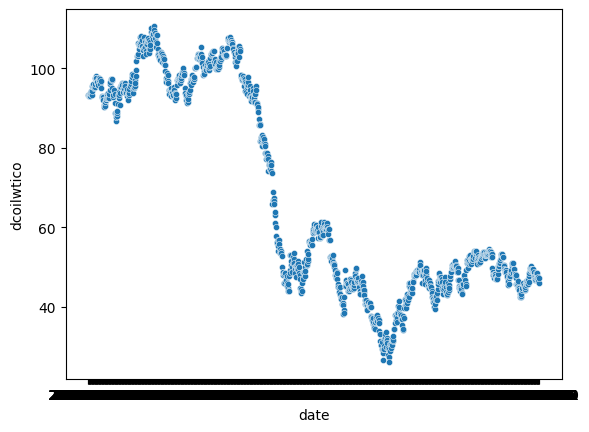

In [8]:
sns.scatterplot(x=oil_df['date'],y=oil_df['dcoilwtico'],s=20)

In [9]:
oil_df['dcoilwtico']=oil_df['dcoilwtico'].ffill().bfill()
oil_df.isna().sum().sum()

np.int64(0)

In [10]:
print(f"shape: {stores_df.shape}")
stores_df.head()

shape: (54, 5)


,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13
1,2,Quito,Pichincha,D,13
2,3,Quito,Pichincha,D,8
3,4,Quito,Pichincha,D,9
4,5,Santo Domingo,Santo Domingo de los Tsachilas,D,4


In [11]:
stores_df=stores_df.rename(columns={'type':'store_type'})
stores_df.dtypes

store_nbr      int64
city          object
state         object
store_type    object
cluster        int64
dtype: object

In [12]:
stores_df.isna().sum().sum()

np.int64(0)

In [13]:
for i,col in enumerate(stores_df.columns):
    print(f"{i+1}->    Feature:{col}            ({stores_df[col].nunique()} unique values)             {stores_df[col].unique()}")

1->    Feature:store_nbr            (54 unique values)             [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48
 49 50 51 52 53 54]
2->    Feature:city            (22 unique values)             ['Quito' 'Santo Domingo' 'Cayambe' 'Latacunga' 'Riobamba' 'Ibarra'
 'Guaranda' 'Puyo' 'Ambato' 'Guayaquil' 'Salinas' 'Daule' 'Babahoyo'
 'Quevedo' 'Playas' 'Libertad' 'Cuenca' 'Loja' 'Machala' 'Esmeraldas'
 'Manta' 'El Carmen']
3->    Feature:state            (16 unique values)             ['Pichincha' 'Santo Domingo de los Tsachilas' 'Cotopaxi' 'Chimborazo'
 'Imbabura' 'Bolivar' 'Pastaza' 'Tungurahua' 'Guayas' 'Santa Elena'
 'Los Rios' 'Azuay' 'Loja' 'El Oro' 'Esmeraldas' 'Manabi']
4->    Feature:store_type            (5 unique values)             ['D' 'B' 'C' 'E' 'A']
5->    Feature:cluster            (17 unique values)             [13  8  9  4  6 15  7  3 12 16  1 10  2  5 11 14 17]


In [14]:
print(f"shape: {hol_event_df.shape}")
hol_event_df.head()

shape: (350, 6)


,date,type,locale,locale_name,description,transferred
0,2012-03-02,Holiday,Local,Manta,Fundacion de Manta,False
1,2012-04-01,Holiday,Regional,Cotopaxi,Provincializacion de Cotopaxi,False
2,2012-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,False
3,2012-04-14,Holiday,Local,Libertad,Cantonizacion de Libertad,False
4,2012-04-21,Holiday,Local,Riobamba,Cantonizacion de Riobamba,False


In [15]:
hol_event_df.dtypes

date           object
type           object
locale         object
locale_name    object
description    object
transferred      bool
dtype: object

In [16]:
hol_event_df.isna().sum().sum()

np.int64(0)

In [17]:
print(f"1->   Feature:date                ({hol_event_df['date'].nunique()} unique values)")
print(f"1->   Feature:description         ({hol_event_df['description'].nunique()} unique values)")
for i,col in enumerate(['type','locale','locale_name','transferred']):
    print(f"{i+2}->   Feature:{col}            ({hol_event_df[col].nunique()} unique values)             {hol_event_df[col].unique()}") 

1->   Feature:date                (312 unique values)
1->   Feature:description         (103 unique values)
2->   Feature:type            (6 unique values)             ['Holiday' 'Transfer' 'Additional' 'Bridge' 'Work Day' 'Event']
3->   Feature:locale            (3 unique values)             ['Local' 'Regional' 'National']
4->   Feature:locale_name            (24 unique values)             ['Manta' 'Cotopaxi' 'Cuenca' 'Libertad' 'Riobamba' 'Puyo' 'Guaranda'
 'Imbabura' 'Latacunga' 'Machala' 'Santo Domingo' 'El Carmen' 'Cayambe'
 'Esmeraldas' 'Ecuador' 'Ambato' 'Ibarra' 'Quevedo'
 'Santo Domingo de los Tsachilas' 'Santa Elena' 'Quito' 'Loja' 'Salinas'
 'Guayaquil']
5->   Feature:transferred            (2 unique values)             [False  True]


In [18]:
hol_event_df=hol_event_df.rename(columns={'type':'day_type'})
main_oil_df=pd.merge(main_df,oil_df,on='date',how='left')
main_oil_df.shape

(3000888, 7)

In [19]:
main_oil_df.isna().sum()

id                  0
date                0
store_nbr           0
family              0
sales               0
onpromotion         0
dcoilwtico     857142
dtype: int64

In [20]:
missing_dates=list(set(main_df['date'].unique())-set(oil_df['date'].unique()))
print(main_df[main_df['date'].isin(missing_dates)].shape)
main_df[main_df['date'].isin(missing_dates)].head(10)


(857142, 6)


,id,date,store_nbr,family,sales,onpromotion
7128,7128,2013-01-05,1,AUTOMOTIVE,5.000,0
7129,7129,2013-01-05,1,BABY CARE,0.000,0
7130,7130,2013-01-05,1,BEAUTY,3.000,0
7131,7131,2013-01-05,1,BEVERAGES,1160.000,0
7132,7132,2013-01-05,1,BOOKS,0.000,0
7133,7133,2013-01-05,1,BREAD/BAKERY,301.057,0
7134,7134,2013-01-05,1,CELEBRATION,0.000,0
7135,7135,2013-01-05,1,CLEANING,811.000,0
7136,7136,2013-01-05,1,DAIRY,464.000,0
7137,7137,2013-01-05,1,DELI,118.613,0


In [21]:
missing_dates_parsed = pd.to_datetime(list(missing_dates))
pd.Series(missing_dates_parsed.day_name()).value_counts()

Saturday    241
Sunday      240
Name: count, dtype: int64

In [22]:
oil_df['date'] = pd.to_datetime(oil_df['date'])
oil_df = (oil_df.set_index('date').asfreq('D').reset_index())
oil_df[pd.to_datetime(list(oil_df['date'])).day_name().isin(['Saturday','Sunday'])].shape

(486, 2)

In [23]:
oil_df['date']=oil_df['date'].astype(str)
oil_df['dcoilwtico']=oil_df['dcoilwtico'].ffill().bfill()
oil_df['dcoilwtico'].isna().sum()

np.int64(0)

In [24]:
main_oil_df2=pd.merge(main_df,oil_df,on='date',how='left')
main_oil_stores_df=pd.merge(main_oil_df2,stores_df,on='store_nbr',how='left')
main_oil_stores_df.shape

(3000888, 11)

In [25]:
main_oil_stores_df.isna().sum().sum()

np.int64(0)

In [26]:
#no. of dates present in main_oil_stores_df but missing in hol_event_df
len(list(set(main_oil_stores_df['date'].unique())-set(hol_event_df['date'].unique())))

1432

In [27]:
hol_event_df[hol_event_df['transferred']] 

,date,day_type,locale,locale_name,description,transferred
19,2012-10-09,Holiday,National,Ecuador,Independencia de Guayaquil,True
72,2013-10-09,Holiday,National,Ecuador,Independencia de Guayaquil,True
135,2014-10-09,Holiday,National,Ecuador,Independencia de Guayaquil,True
255,2016-05-24,Holiday,National,Ecuador,Batalla de Pichincha,True
266,2016-07-25,Holiday,Local,Guayaquil,Fundacion de Guayaquil,True
268,2016-08-10,Holiday,National,Ecuador,Primer Grito de Independencia,True
297,2017-01-01,Holiday,National,Ecuador,Primer dia del ano,True
303,2017-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,True
312,2017-05-24,Holiday,National,Ecuador,Batalla de Pichincha,True
324,2017-08-10,Holiday,National,Ecuador,Primer Grito de Independencia,True


In [28]:
hol_event_df[hol_event_df['day_type']=='Transfer']

,date,day_type,locale,locale_name,description,transferred
20,2012-10-12,Transfer,National,Ecuador,Traslado Independencia de Guayaquil,False
73,2013-10-11,Transfer,National,Ecuador,Traslado Independencia de Guayaquil,False
136,2014-10-10,Transfer,National,Ecuador,Traslado Independencia de Guayaquil,False
256,2016-05-27,Transfer,National,Ecuador,Traslado Batalla de Pichincha,False
265,2016-07-24,Transfer,Local,Guayaquil,Traslado Fundacion de Guayaquil,False
269,2016-08-12,Transfer,National,Ecuador,Traslado Primer Grito de Independencia,False
298,2017-01-02,Transfer,National,Ecuador,Traslado Primer dia del ano,False
304,2017-04-13,Transfer,Local,Cuenca,Fundacion de Cuenca,False
313,2017-05-26,Transfer,National,Ecuador,Traslado Batalla de Pichincha,False
325,2017-08-11,Transfer,National,Ecuador,Traslado Primer Grito de Independencia,False


In [29]:
#converting holidays  which are transferred from  to workday
hol_event_df.loc[hol_event_df['transferred'], 'day_type'] = 'Work Day'
hol_event_df.loc[hol_event_df['day_type']=='Transfer']='Holiday'
hol_event_df=hol_event_df.drop(columns=['transferred'])

#duplicates of dates in hol_event_df dataframe 
print(hol_event_df["date"].duplicated().sum())

holiday_duplicate_dates_df = hol_event_df[hol_event_df["date"].duplicated(keep=False)]
holiday_duplicate_dates_df.sort_values("date").head(10)

47


/tmp/ipykernel_71855/3852816816.py:3: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'Holiday' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  hol_event_df.loc[hol_event_df['day_type']=='Transfer']='Holiday'


,date,day_type,locale,locale_name,description
7,2012-06-25,Holiday,Regional,Imbabura,Provincializacion de Imbabura
8,2012-06-25,Holiday,Local,Latacunga,Cantonizacion de Latacunga
9,2012-06-25,Holiday,Local,Machala,Fundacion de Machala
10,2012-07-03,Holiday,Local,Santo Domingo,Fundacion de Santo Domingo
11,2012-07-03,Holiday,Local,El Carmen,Cantonizacion de El Carmen
32,2012-12-22,Holiday,Local,Salinas,Cantonizacion de Salinas
33,2012-12-22,Additional,National,Ecuador,Navidad-3
36,2012-12-24,Additional,National,Ecuador,Navidad-1
35,2012-12-24,Bridge,National,Ecuador,Puente Navidad
39,2012-12-31,Bridge,National,Ecuador,Puente Primer dia del ano


In [30]:
hol_event_df_final = hol_event_df.groupby('date').agg(
    lambda x: x.unique().tolist()
).reset_index()

print(f"Total unique dates: {len(hol_event_df_final)}")

Total unique dates: 303


In [31]:
hol_event_df_final.head(10)

,date,day_type,locale,locale_name,description
0,2012-03-02,[Holiday],[Local],[Manta],[Fundacion de Manta]
1,2012-04-01,[Holiday],[Regional],[Cotopaxi],[Provincializacion de Cotopaxi]
2,2012-04-12,[Holiday],[Local],[Cuenca],[Fundacion de Cuenca]
3,2012-04-14,[Holiday],[Local],[Libertad],[Cantonizacion de Libertad]
4,2012-04-21,[Holiday],[Local],[Riobamba],[Cantonizacion de Riobamba]
5,2012-05-12,[Holiday],[Local],[Puyo],[Cantonizacion del Puyo]
6,2012-06-23,[Holiday],[Local],[Guaranda],[Cantonizacion de Guaranda]
7,2012-06-25,[Holiday],"[Regional, Local]","[Imbabura, Latacunga, Machala]","[Provincializacion de Imbabura, Cantonizacion ..."
8,2012-07-03,[Holiday],[Local],"[Santo Domingo, El Carmen]","[Fundacion de Santo Domingo, Cantonizacion de ..."
9,2012-07-23,[Holiday],[Local],[Cayambe],[Cantonizacion de Cayambe]


In [32]:
full_df=pd.merge(main_oil_stores_df,hol_event_df_final,on='date',how='left')
print(f"shape:{full_df.shape}")
full_df.isna().sum()

shape:(3000888, 15)


id                   0
date                 0
store_nbr            0
family               0
sales                0
onpromotion          0
dcoilwtico           0
city                 0
state                0
store_type           0
cluster              0
day_type       2566080
locale         2566080
locale_name    2566080
description    2566080
dtype: int64

In [33]:
full_df['day_type']=full_df['day_type'].fillna('no_day_type')
full_df['locale']=full_df['locale'].fillna('no_locale')
full_df['locale_name']=full_df['locale_name'].fillna('no_locale_name')
full_df['description']=full_df['description'].fillna('no_description')

In [34]:
full_df['date']=pd.to_datetime(full_df['date'])
full_df['year']=full_df['date'].dt.year
full_df['monthofyear']=full_df['date'].dt.month
full_df['dayofmonth']=full_df['date'].dt.day
full_df['dayofweek']=full_df['date'].dt.dayofweek
full_df['is_weekend']=full_df['dayofweek'].isin([5,6])
full_df.isna().sum().sum()

np.int64(0)

In [35]:
full_df.dtypes

id                      int64
date           datetime64[ns]
store_nbr               int64
family                 object
sales                 float64
onpromotion             int64
dcoilwtico            float64
city                   object
state                  object
store_type             object
cluster                 int64
day_type               object
locale                 object
locale_name            object
description            object
year                    int32
monthofyear             int32
dayofmonth              int32
dayofweek               int32
is_weekend               bool
dtype: object

In [36]:
full_df['store_nbr']=full_df['store_nbr'].astype('object')
full_df['cluster']=full_df['cluster'].astype('object')

In [37]:
full_df=full_df.drop(columns=['date'])
from sklearn.model_selection import train_test_split 
y=full_df['sales']
x=full_df.drop(columns=['sales'])
x_train,x_test,y_train,y_test=train_test_split(x,y,random_state=42)
x_train=x_train.drop(columns=['id'])
x_test=x_test.drop(columns=['id'])

In [38]:
del main_df,oil_df,stores_df,hol_event_df,hol_event_df_final
del missing_dates_parsed,missing_dates,holiday_duplicate_dates_df
del main_oil_df,main_oil_df2,main_oil_stores_df
del full_df,x,y

In [39]:
x_train.head()

,store_nbr,family,onpromotion,dcoilwtico,city,state,store_type,cluster,day_type,locale,locale_name,description,year,monthofyear,dayofmonth,dayofweek,is_weekend
2886109,38,POULTRY,0,46.10,Loja,Loja,D,4,no_day_type,no_locale,no_locale_name,no_description,2017,6,12,0,False
1308436,21,LADIESWEAR,0,48.69,Santo Domingo,Santo Domingo de los Tsachilas,B,6,no_day_type,no_locale,no_locale_name,no_description,2015,1,7,2,False
2505116,48,LAWN AND GARDEN,0,45.20,Quito,Pichincha,A,14,no_day_type,no_locale,no_locale_name,no_description,2016,11,9,2,False
916601,27,PET SUPPLIES,0,103.40,Daule,Guayas,D,1,no_day_type,no_locale,no_locale_name,no_description,2014,5,31,5,True
470668,15,"LIQUOR,WINE,BEER",0,104.70,Ibarra,Imbabura,C,15,no_day_type,no_locale,no_locale_name,no_description,2013,9,22,6,True


In [40]:
x_train.dtypes

store_nbr       object
family          object
onpromotion      int64
dcoilwtico     float64
city            object
state           object
store_type      object
cluster         object
day_type        object
locale          object
locale_name     object
description     object
year             int32
monthofyear      int32
dayofmonth       int32
dayofweek        int32
is_weekend        bool
dtype: object

In [41]:
x_train.shape

(2250666, 17)

<Axes: xlabel='sales'>

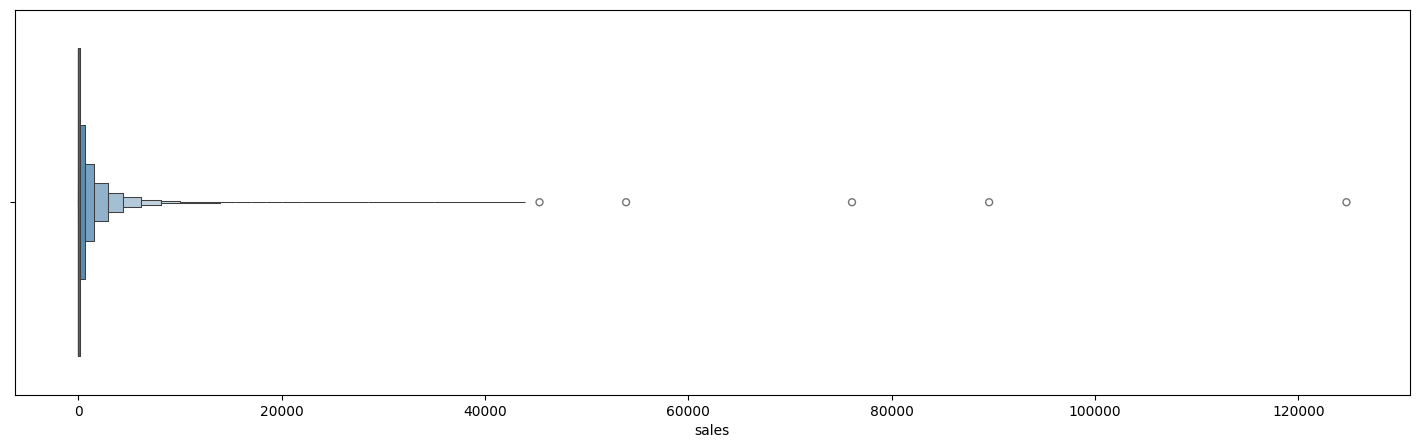

In [42]:
plt.figure(figsize=(18,5))
sns.boxenplot(x=y_train,orient='h')

In [43]:
x_train.loc[y_train[y_train>40000].index]

,store_nbr,family,onpromotion,dcoilwtico,city,state,store_type,cluster,day_type,locale,locale_name,description,year,monthofyear,dayofmonth,dayofweek,is_weekend
2145045,45,GROCERY I,44,43.18,Quito,Pichincha,A,11,"[Holiday, Event]","[Local, National]","[Riobamba, Ecuador]","[Cantonizacion de Riobamba, Terremoto Manabi+5]",2016,4,21,3,False
2163723,2,GROCERY I,59,44.75,Quito,Pichincha,D,13,[Event],[National],[Ecuador],[Terremoto Manabi+16],2016,5,2,0,False
1257246,35,GROCERY I,3,63.13,Playas,Guayas,C,3,[Holiday],[Local],[Loja],[Fundacion de Loja],2014,12,8,0,False
2445984,39,MEATS,0,49.76,Cuenca,Azuay,B,6,[Holiday],[Local],[Quevedo],[Cantonizacion de Quevedo],2016,10,7,4,False
1916586,35,GROCERY I,7,36.31,Playas,Guayas,C,3,no_day_type,no_locale,no_locale_name,no_description,2015,12,14,0,False
2139699,45,GROCERY I,38,39.74,Quito,Pichincha,A,11,[Event],[National],[Ecuador],[Terremoto Manabi+2],2016,4,18,0,False


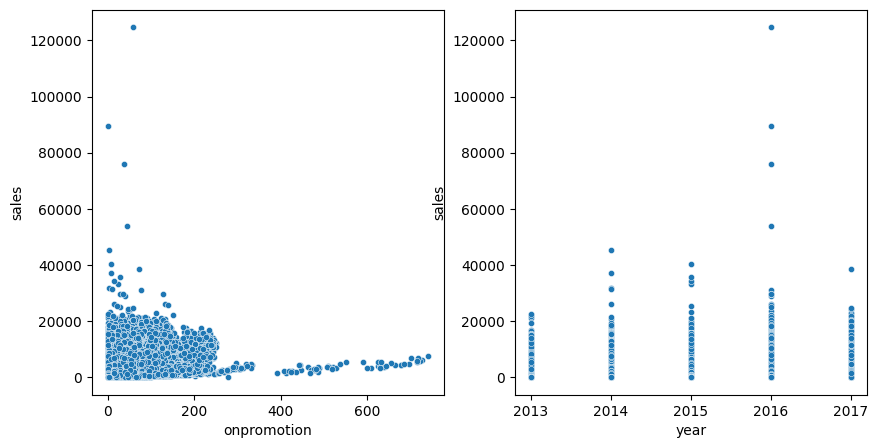

In [44]:
features=['onpromotion','year']
fig,axes=plt.subplots(1,2,figsize=(10,5))
axes=axes.flatten()
for i,feature in enumerate(features):
    sns.scatterplot(x=x_train[feature],y=y_train,ax=axes[i],s=20)
    
del features,fig,axes

outliers are present ,maybe due to 2016's ecuador's earthquake 

In [45]:
mul_bin_cat_featuress=['day_type','locale','locale_name','description']
normal_time_series_features=['monthofyear','dayofweek']
normal_cat_features=['store_nbr','family','city','state','cluster','store_type']

In [47]:
from sklearn.preprocessing import MultiLabelBinarizer,OneHotEncoder
from sklearn.base import BaseEstimator,TransformerMixin
from feature_engine.creation import CyclicalFeatures
from sklearn.compose import ColumnTransformer

class mymlb(BaseEstimator, TransformerMixin):
    def fit(self, x, y=None):
        self.encoder = MultiLabelBinarizer(sparse_output=True)
        self.encoder.fit(x.iloc[:,0])
        return self

    def transform(self, x):
        return self.encoder.transform(x.iloc[:,0])

    def get_feature_names_out(self,input_features=None):
        return self.encoder.classes_

class mycfe(BaseEstimator,TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        month = X['monthofyear'].to_numpy()
        day = X['dayofmonth'].to_numpy()

        days_in_month = np.select( 
            [
                np.isin(month, [1, 3, 5, 7, 8, 10, 12]),
                np.isin(month, [4, 6, 9, 11]),
                month == 2
            ],
            [31, 30, 28],
            default=np.nan
        )

        angle = 2 * np.pi * (day - 1) / days_in_month

        return np.column_stack([
            np.sin(angle),
            np.cos(angle)
        ])

    def get_feature_names_out(self, input_features=None):
        return np.array(['day_sin', 'day_cos'], dtype=object)


preprocessor=ColumnTransformer(transformers=[
    ('onehot_encoder',OneHotEncoder(sparse_output=True),normal_cat_features),
    ('mulbin_encoder1',mymlb(),['day_type']),
    ('mulbin_encoder2',mymlb(),['locale']),
    ('mulbin_encoder3',mymlb(),['locale_name']),
    ('mulbin_encoder4',mymlb(),['description']),
    ('cyclic_encoder1',CyclicalFeatures(),normal_time_series_features),
    ('cyclic_encoder2',mycfe(),['dayofmonth','monthofyear'])                          # for cyclicalencoding of dayofmonth ( cause different months have different maximum dayofmonths )
])
x_train_processed=preprocessor.fit_transform(x_train)
x_test_processed=preprocessor.transform(x_test)


In [48]:
del x_train,x_test
encoded_features=preprocessor.get_feature_names_out()
x_train_processed.shape

(2250666, 318)

- Uncomment to calculate and see mutual information , takes few minutes

In [ ]:
# from sklearn.feature_selection import mutual_info_regression
# rng=np.random.default_rng(seed=42)
# idx=np.sort(rng.choice(x_train_processed.shape[0], size=400000, replace=False))
# x_train_processed_sample=x_train_processed[idx]
# y_train_sample=y_train.iloc[idx]
# mi_scores = mutual_info_regression(
#     x_train_processed_sample,
#     y_train_sample,
#     discrete_features=True,
#     random_state=1
# )
# mi_scores = pd.Series(
#     mi_scores,
#     index=encoded_features,
#     name='MI_score'
# ).sort_values(ascending=False)
# del idx,x_train_processed_sample,y_train_sample

<Axes: ylabel='None'>

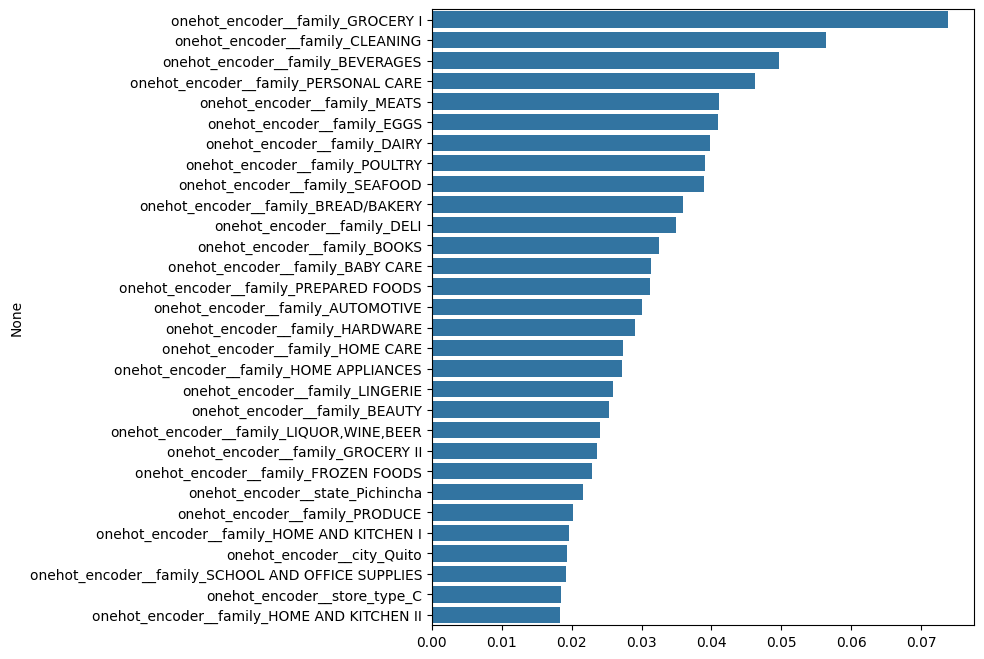

In [ ]:
# plt.figure(figsize=(7,8))
# sns.barplot(x=mi_scores.head(30).values,y=mi_scores.head(30).index,orient='h')

In [50]:
from xgboost import XGBRegressor
test_model=XGBRegressor(random_state=42,device='cuda',objective='reg:tweedie',tweedie_variance_power=1.5) # replace 'cuda' with 'cpu' if you don't have nvidia gpu
test_model.fit(x_train_processed,y_train)

,objective,'reg:tweedie'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,'cuda'
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,None


In [51]:
from sklearn.metrics import root_mean_squared_log_error,r2_score
y_predict=test_model.predict(x_test_processed)
root_mean_squared_log_error(y_test,y_predict)

/home/umesh/ML/.venv/lib/python3.14/site-packages/xgboost/core.py:569: UserWarning: [23:38:36] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


1.456177475848809

Text(0.5, 1.0, 'Sales from test set with log1p transform')

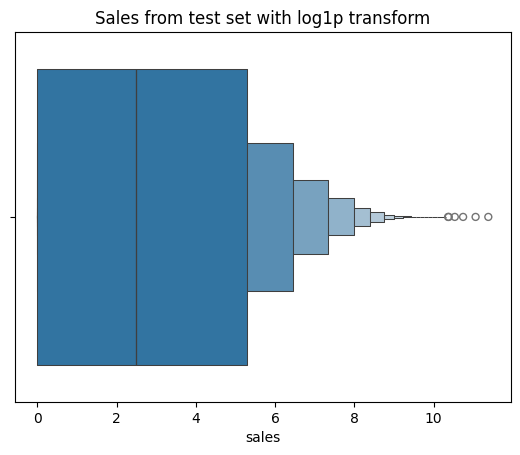

In [57]:
y_test_log=np.log1p(y_test)
y_test_log_plot=sns.boxenplot(x=y_test_log,orient='h')
y_test_log_plot.set_title('Sales from test set with log1p transform')

In [58]:
root_mean_squared_log_error(y_train,test_model.predict(x_train_processed))

1.4560425068222322

In [53]:
test_model.score(x_test_processed,y_test)

0.8206576120160555

In [54]:
test_model.score(x_train_processed,y_train)

0.8245956061999917

- These metrics show that there is no overfitting 

<Axes: xlabel='importance', ylabel='feature'>

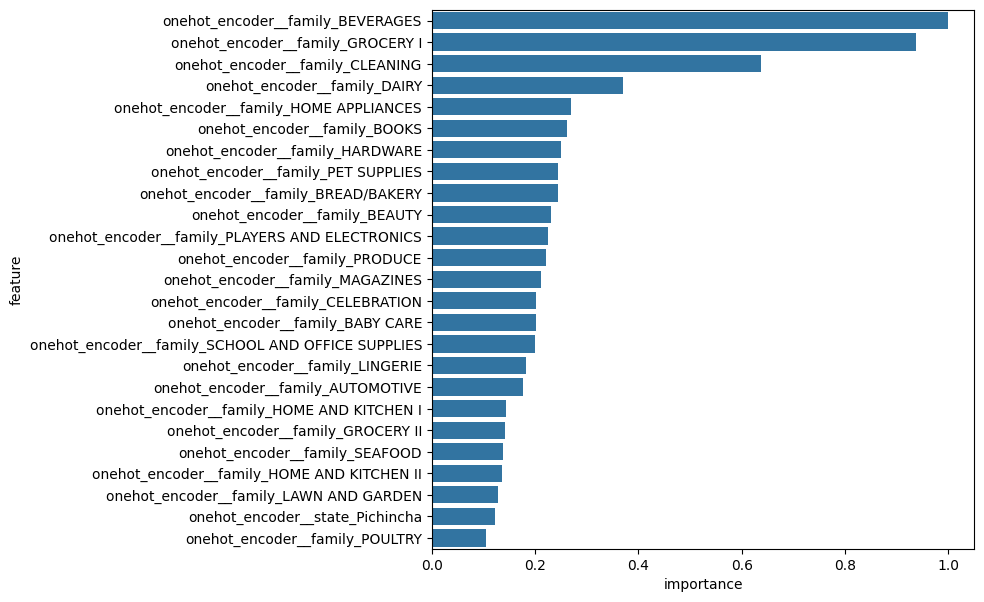

In [60]:
from sklearn.preprocessing import MinMaxScaler
test_model.get_booster().feature_names=list(encoded_features)
importance_dict = test_model.get_booster().get_score(importance_type='gain')

importance_df = pd.DataFrame({'feature': list(importance_dict.keys()),'importance': list(importance_dict.values())
}).sort_values(by='importance', ascending=False)

scaler=MinMaxScaler()
importance_df['importance']=scaler.fit_transform(importance_df[['importance']])
plt.figure(figsize=(7,7))
sns.barplot(data=importance_df.head(25),x='importance',y='feature')

In [61]:
importance_df.sort_values(by='importance',ascending=True)[40:60]

,feature,importance
172,mulbin_encoder4__Primer dia del ano-1,0.000099
124,mulbin_encoder3__Cayambe,0.000120
173,mulbin_encoder4__Provincializacion de Cotopaxi,0.000137
126,mulbin_encoder3__El Carmen,0.000153
125,mulbin_encoder3__Cuenca,0.000167
206,mulbin_encoder4___,0.000179
29,onehot_encoder__store_nbr_31,0.000214
176,mulbin_encoder4__Puente Dia de Difuntos,0.000226
179,mulbin_encoder4__Recupero Puente Navidad,0.000226
147,mulbin_encoder4__Dia de la Madre-1,0.000232


In [62]:
less_importance_features=list(importance_df[importance_df['importance']<0.002]['feature'])
important_features= ~np.isin(encoded_features,less_importance_features)

x_train_processed_final=x_train_processed[:,important_features]
x_test_processed_final=x_test_processed[:,important_features]

In [ ]:
from sklearn.model_selection import GridSearchCV

test_model2=XGBRegressor(random_state=42,subsample=0.7,device='cuda',objective='reg:tweedie',tweedie_variance_power=1.5)
params_grid={
    'learning_rate':[0.01,0.1,0.2],
    'n_estimators':[100,200],
    'max_depth':[5,8,11],
    'min_child_weight':[3,5,7],
}
grid=GridSearchCV(estimator=test_model2,param_grid=params_grid,cv=4,scoring='neg_mean_squared_log_error')
grid.fit(x_train_processed_final,y_train)

,estimator,"XGBRegressor(...ree=None, ...)"
,param_grid,"{'learning_rate': [0.01, 0.1, ...], 'max_depth': [5, 8, ...], 'min_child_weight': [3, 5, ...], 'n_estimators': [100, 200]}"
,scoring,'neg_mean_squared_log_error'
,n_jobs,None
,refit,True
,cv,4
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,objective,'reg:tweedie'


In [ ]:
grid.best_params_

{'learning_rate': 0.2,
 'max_depth': 11,
 'min_child_weight': 7,
 'n_estimators': 200}

In [ ]:
from sklearn.metrics import r2_score,root_mean_squared_log_error
y_predict2=grid.best_estimator_.predict(x_test_processed_final)
print(r2_score(y_test,y_predict2))
y_train_predict2=grid.best_estimator_.predict(x_train_processed_final)
r2_score(y_train,y_train_predict2)

0.8109629484635342


0.8303151630567923

likely to have overfitting prblem

In [63]:
final_model=XGBRegressor(random_state=42,subsample=0.6,device='cuda',learning_rate=0.2,max_depth=9,n_estimators=300,reg_lambda=30,min_child_weight=7,gamma=8,
                         colsample_bytree=0.6,verbosity=0,tree_method='hist',sampling_method='gradient_based',objective='reg:tweedie',tweedie_variance_power=1.45)
final_model.fit(x_train_processed_final,y_train)

,objective,'reg:tweedie'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.6
,device,'cuda'
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,None


In [64]:
y_predict_final=final_model.predict(x_test_processed_final)
print('r2_score:',r2_score(y_test,y_predict_final))
print('root_mean_squared_log_error:',root_mean_squared_log_error(y_test,y_predict_final))
y_train_predict_final=final_model.predict(x_train_processed_final)
print('\n\nr2_score for trainin set:',r2_score(y_train,y_train_predict_final))

r2_score: 0.8149432700164531
root_mean_squared_log_error: 1.4347323263431118


r2_score for trainin set: 0.8242098199115361


In [65]:

encoded_arr = np.array(encoded_features)
trained_feature_names = encoded_arr[
    ~np.isin(encoded_arr, less_importance_features)
].tolist()

import shap
explainer=shap.TreeExplainer(final_model)
x_test_dense=x_test_processed_final.toarray()
x_test_for_shap=pd.DataFrame(x_test_dense,columns=trained_feature_names)
shap_values=explainer(x_test_for_shap)


/home/umesh/ML/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


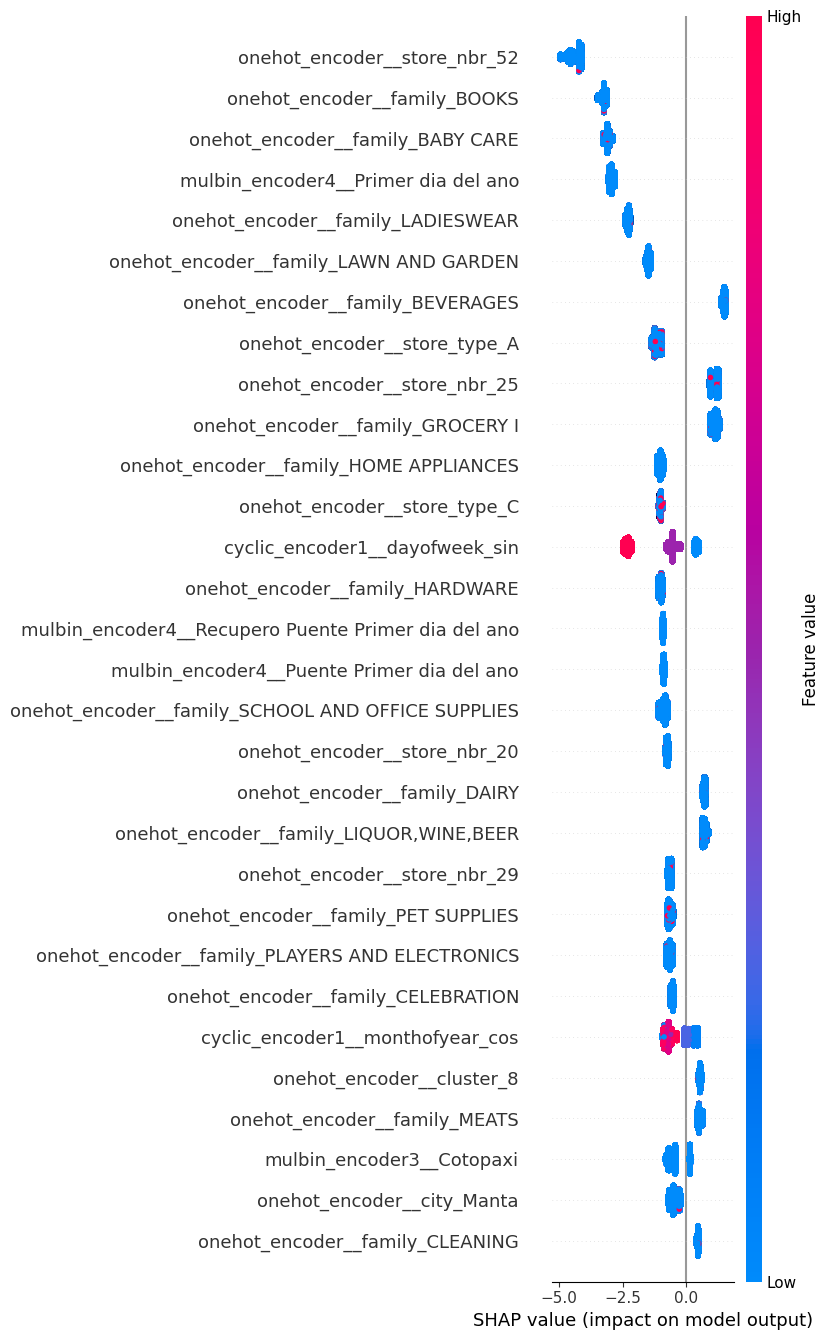

In [66]:
del x_train_processed_final,x_test_processed_final

shap.summary_plot(shap_values,x_test_for_shap,max_display=30)